# Breast Cancer Diagnosis with Logistic Regression from Scratch (Part 1: Before Midsem)

Wisconsin breast cancer dataset (569 samples, 30 numeric features). The goal is to predict whether a tumour is malignant (1) or benign (0) using a Logistic Regression model written manually with NumPy.

This notebook has the EDA, hypotheses, data preparation, the baseline model and its validation (hold-out, cross-validation, repeated cross-validation). Feature selection, SHAP, calibration and noise robustness are in Part 2.

In [361]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Loading the Data

In [362]:
raw_data = pd.read_csv("data.csv")
display(raw_data)

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN


In [363]:
initial_columns = [column for column in raw_data.columns if column != "diagnosis"]
print("initial feature columns:", initial_columns)
print("initial number of feature columns:", len(initial_columns))

initial feature columns: ['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
initial number of feature columns: 32


`id` and `Unnamed: 32` are not useful for prediction, so they are dropped. The target is encoded as M = 1, B = 0.

In [364]:
data = raw_data.copy()
data["diagnosis"] = data["diagnosis"].map({"M": 1, "B": 0})
data = data.drop(["id", "Unnamed: 32"], axis=1)
display(data)

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


## 1. Exploratory Data Analysis

### 1.1 Basic info

In [365]:
features = data.drop("diagnosis", axis=1)

print("the shape of the data is:", data.shape)
print("the feature columns after preprocessing are:", list(features.columns))
print("the number of feature columns after preprocessing are:", features.shape[1])
print("our target column is: diagnosis")

the shape of the data is: (569, 31)
the feature columns after preprocessing are: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']
the number of feature columns after preprocessing are: 30
our target column is: diagnosis


### 1.2 Describing each feature

In [366]:
# transpose so each feature is a row so it is easier to read
# (features only: the target column is not a feature, so it is not described here)
display(features.describe().T)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
fractal_dimension_mean,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


### 1.3 Class distribution

,Diagnosis,Count,Percentage
0,Benign,357,62.741652
1,Malignant,212,37.258348


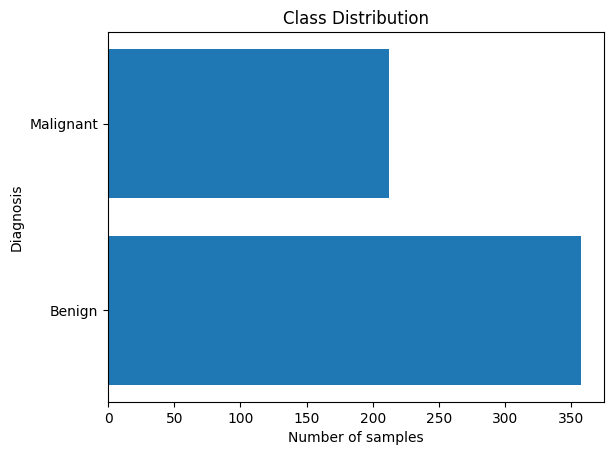

In [367]:
class_counts = data["diagnosis"].value_counts().sort_index()
class_percentages = data["diagnosis"].value_counts(normalize=True).sort_index() * 100

class_summary = pd.DataFrame({
    "Diagnosis": ["Benign", "Malignant"],
    "Count": class_counts.values,
    "Percentage": class_percentages.values
})
display(class_summary)

plt.barh(class_summary["Diagnosis"], class_summary["Count"])
plt.ylabel("Diagnosis")
plt.xlabel("Number of samples")
plt.title("Class Distribution")
plt.show()

### 1.4 Missing values and duplicates

In [368]:
print(data.isnull().sum())
print()
print("the number of missing values are:", data.isnull().sum().sum())
print("the number of duplicate rows are:", data.duplicated().sum())

diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64

the number of missing values are: 0
the number of duplicate rows are: 0


This directly tells us that no feature has any NaN/missing values or duplicate rows, so it is safe to go forward without any changes to the data.

### 1.5 Unique values of each feature

smoothness_worst           411
symmetry_mean              432
radius_mean                456
radius_worst               457
smoothness_mean            474
texture_mean               479
concave points_worst       492
symmetry_se                498
fractal_dimension_mean     499
symmetry_worst             500
concave points_se          507
texture_worst              511
perimeter_worst            514
texture_se                 519
perimeter_mean             522
area_se                    528
compactness_worst          529
concavity_se               533
perimeter_se               533
fractal_dimension_worst    535
concavity_mean             537
compactness_mean           537
area_mean                  539
concavity_worst            539
radius_se                  540
compactness_se             541
concave points_mean        542
area_worst                 544
fractal_dimension_se       545
smoothness_se              547
dtype: int64



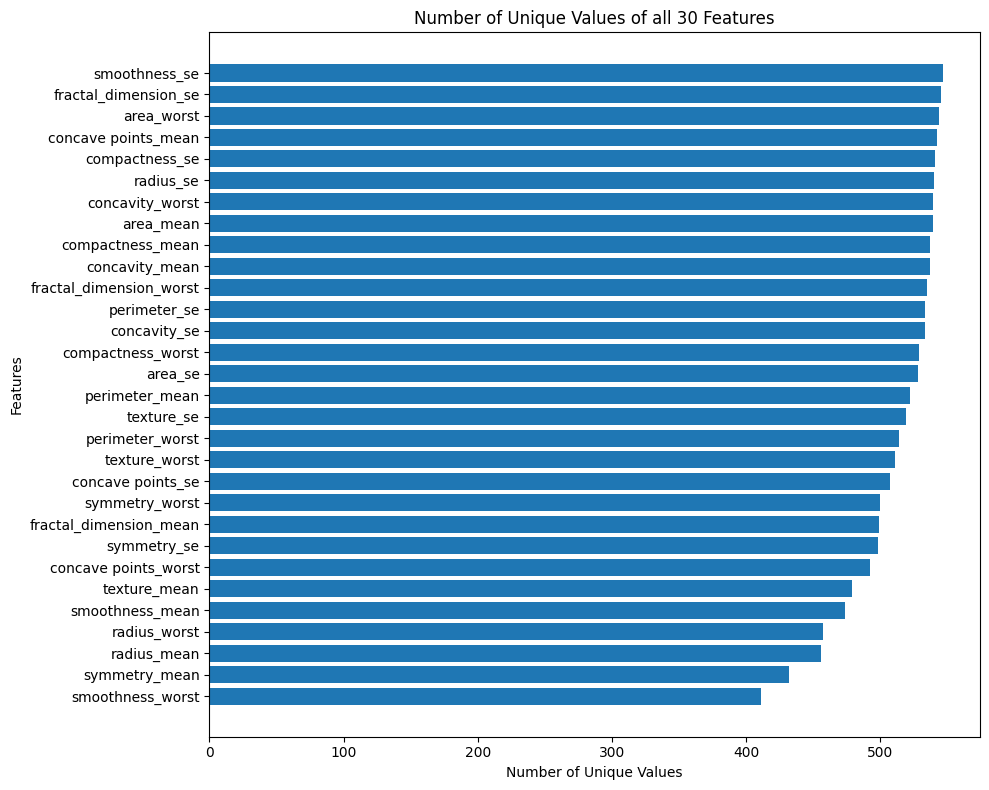

In [369]:
unique_counts = features.nunique().sort_values()
print(unique_counts)
print()
#graphing
plt.figure(figsize=(10, 8))
plt.barh(unique_counts.index, unique_counts.values)
plt.xlabel("Number of Unique Values")
plt.ylabel("Features")
plt.title("Number of Unique Values of all 30 Features")
plt.tight_layout()
plt.show()

No feature has very few unique values, so none of them needs to be removed because of zero variation.

### 1.6 Standard deviations

fractal_dimension_se         0.002646
smoothness_se                0.003003
concave points_se            0.006170
fractal_dimension_mean       0.007060
symmetry_se                  0.008266
smoothness_mean              0.014064
compactness_se               0.017908
fractal_dimension_worst      0.018061
smoothness_worst             0.022832
symmetry_mean                0.027414
concavity_se                 0.030186
concave points_mean          0.038803
compactness_mean             0.052813
symmetry_worst               0.061867
concave points_worst         0.065732
concavity_mean               0.079720
compactness_worst            0.157336
concavity_worst              0.208624
radius_se                    0.277313
texture_se                   0.551648
perimeter_se                 2.021855
radius_mean                  3.524049
texture_mean                 4.301036
radius_worst                 4.833242
texture_worst                6.146258
perimeter_mean              24.298981
perimeter_wo

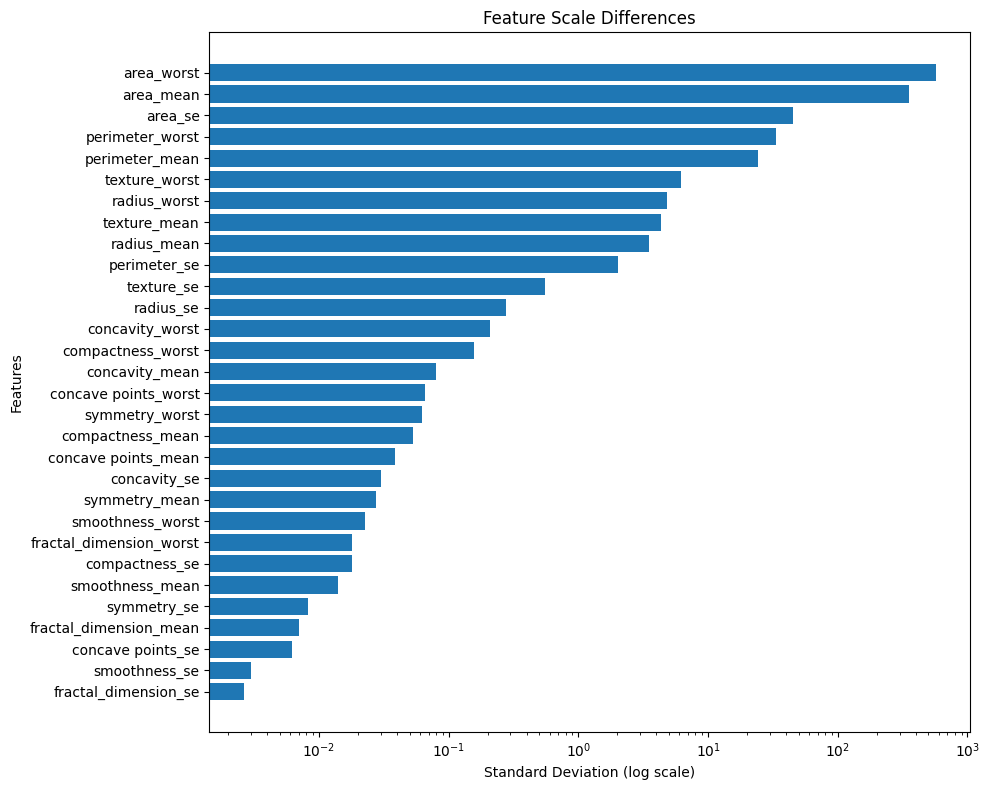

In [370]:
std_values = features.std().sort_values()
print(std_values)
print()

plt.figure(figsize=(10, 8))
plt.barh(std_values.index, std_values.values)
plt.xscale("log")
plt.xlabel("Standard Deviation (log scale)")
plt.ylabel("Features")
plt.title("Feature Scale Differences")
plt.tight_layout()
plt.show()

The 30 features are on very different scales, with standard deviations from about 0.0026 to 569.36. So standardization will probably matter for the model.

### 1.7 Distributions and outliers

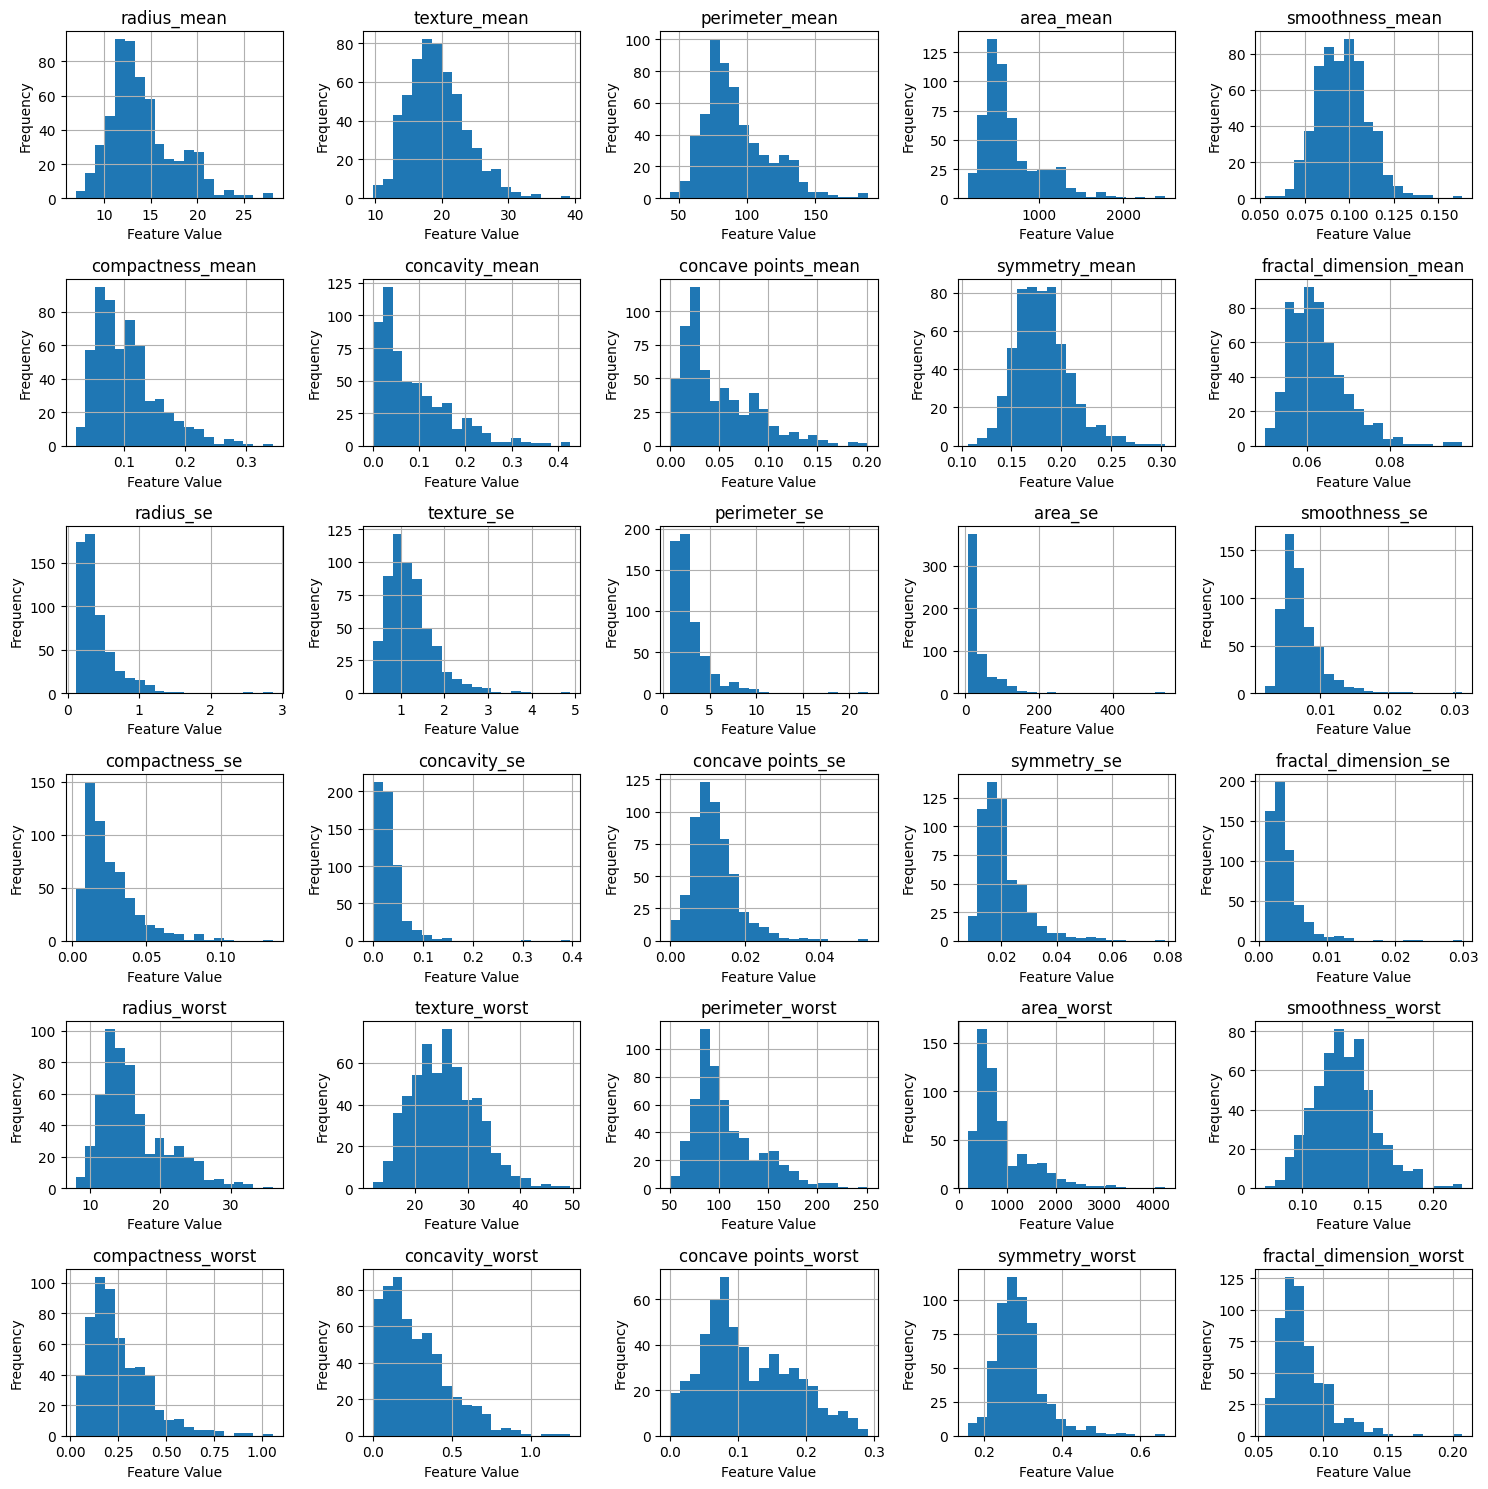

In [371]:
axes = features.hist(figsize=(15, 15), bins=20)

for ax in axes.flatten():
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

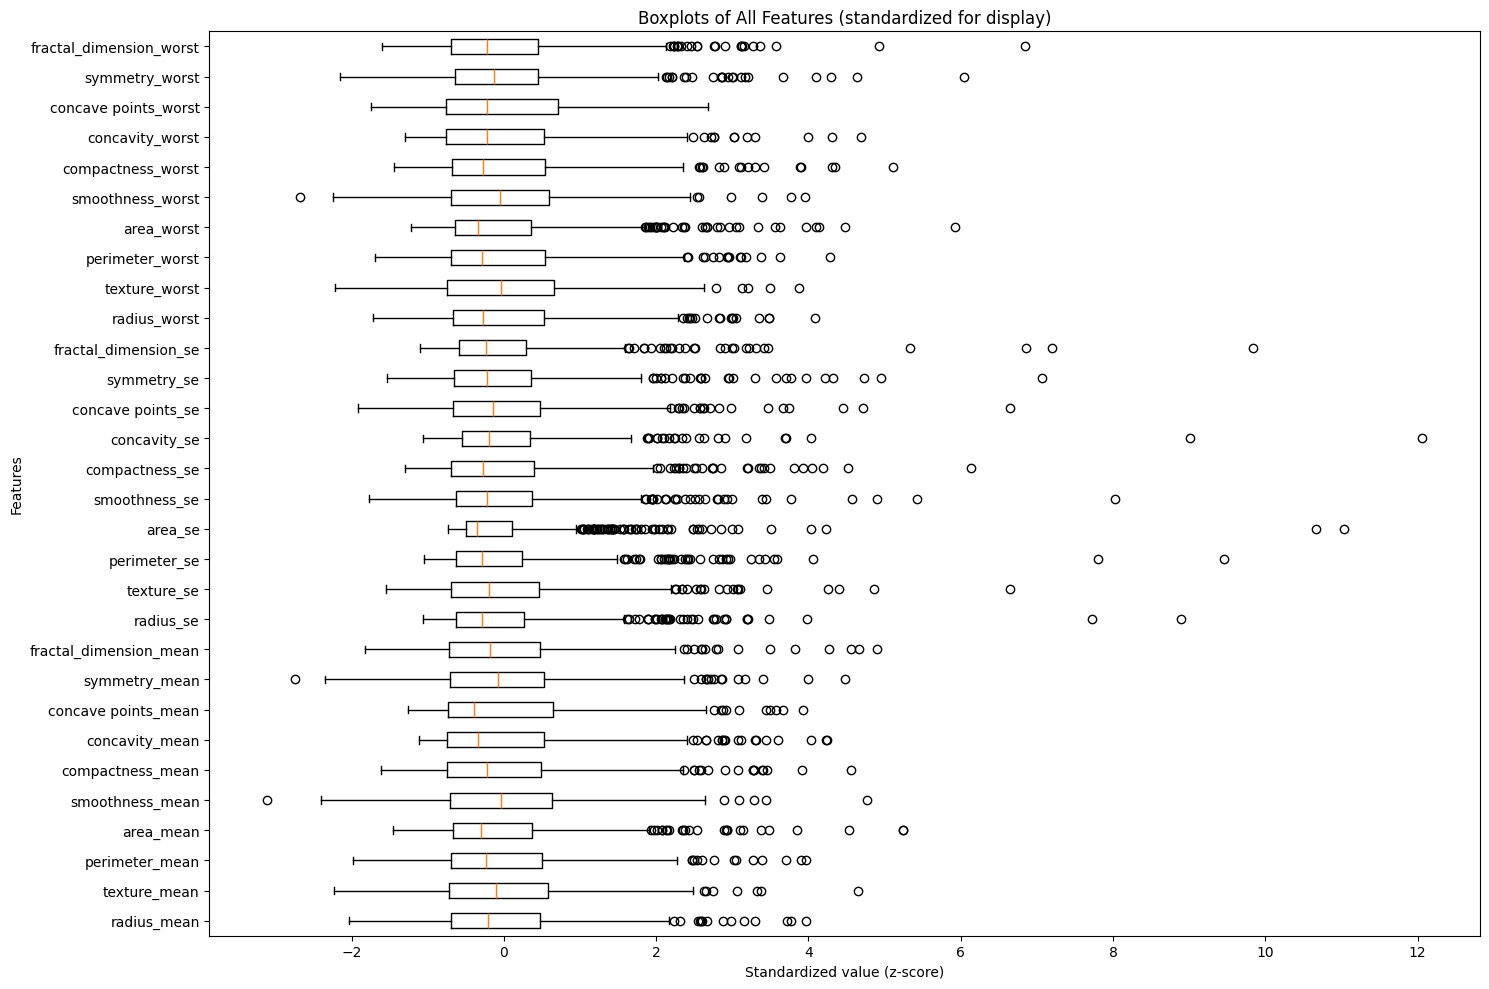

In [372]:
# The raw features have very different scales (see 1.6), so on one axis only area and perimeter are visible.
# z-scores are used here for display only, to make all 30 boxplots comparable. The modelling data is not changed.
display_scaled = (features - features.mean()) / features.std()

plt.figure(figsize=(15, 10))
plt.boxplot(display_scaled.values, vert=False)
plt.yticks(range(1, features.shape[1] + 1), features.columns)
plt.xlabel("Standardized value (z-score)")
plt.ylabel("Features")
plt.title("Boxplots of All Features (standardized for display)")
plt.tight_layout()
plt.show()

### 1.8 Correlation between features

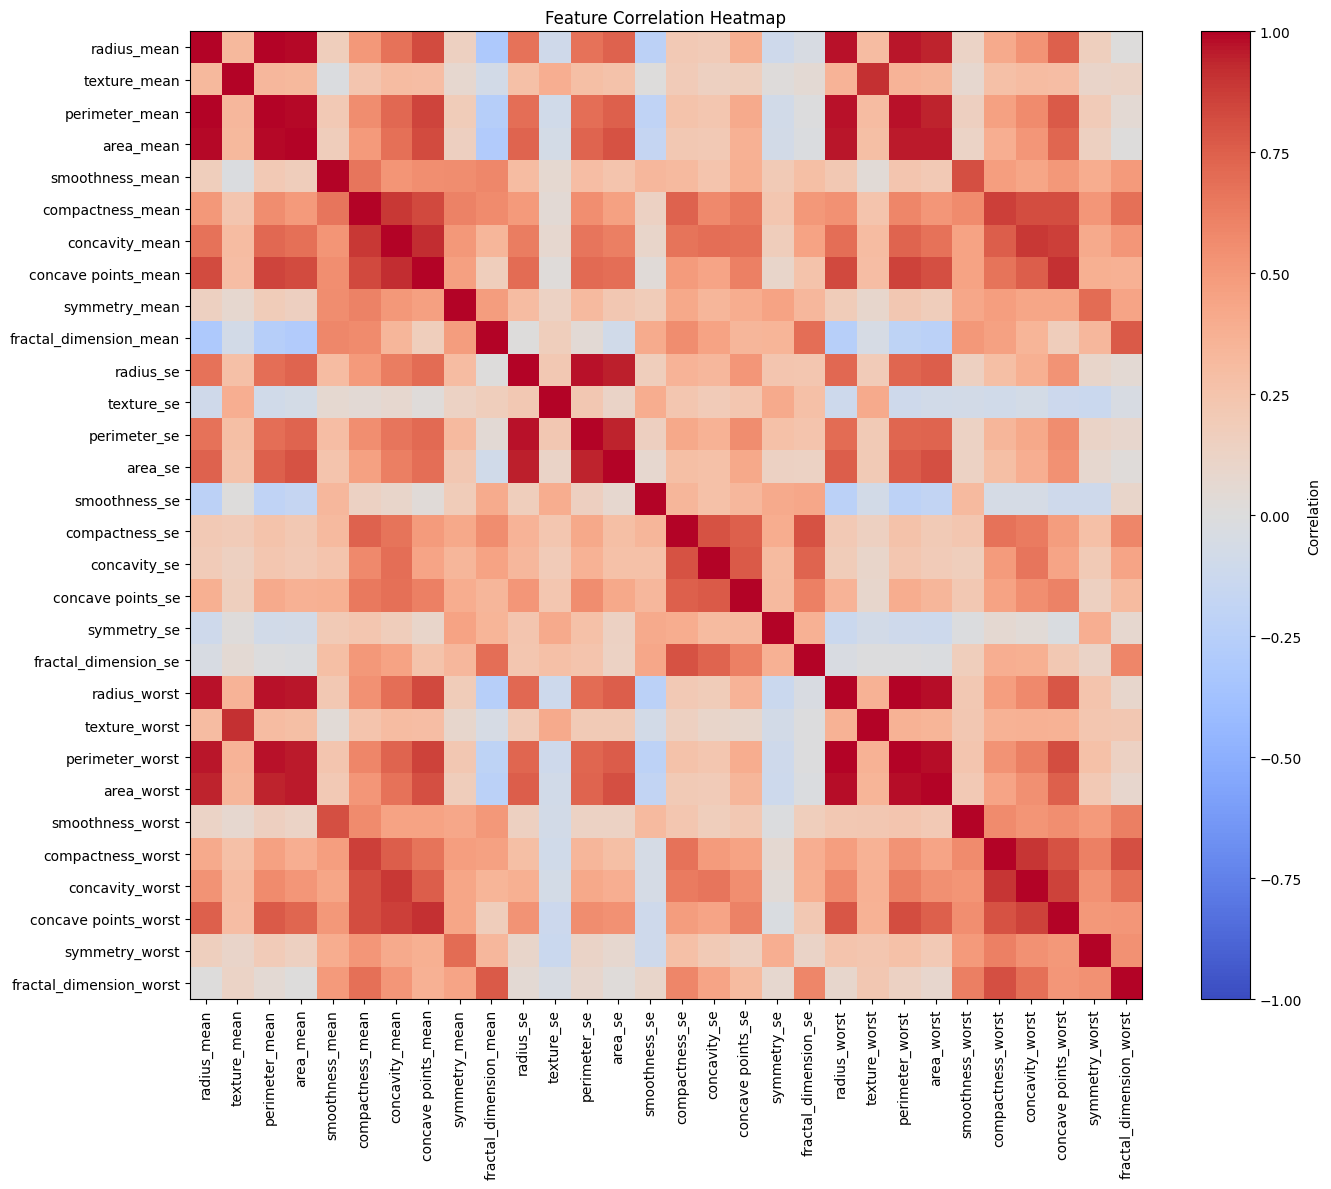

In [373]:
correlation_matrix = features.corr()

plt.figure(figsize=(14, 12))
plt.imshow(correlation_matrix, cmap="coolwarm", aspect="auto", vmin=-1, vmax=1)  # fixed scale so 0 is the neutral colour
plt.colorbar(label="Correlation")
plt.xticks(range(features.shape[1]), features.columns, rotation=90)
plt.yticks(range(features.shape[1]), features.columns)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### 1.9 Benign vs malignant for a few features

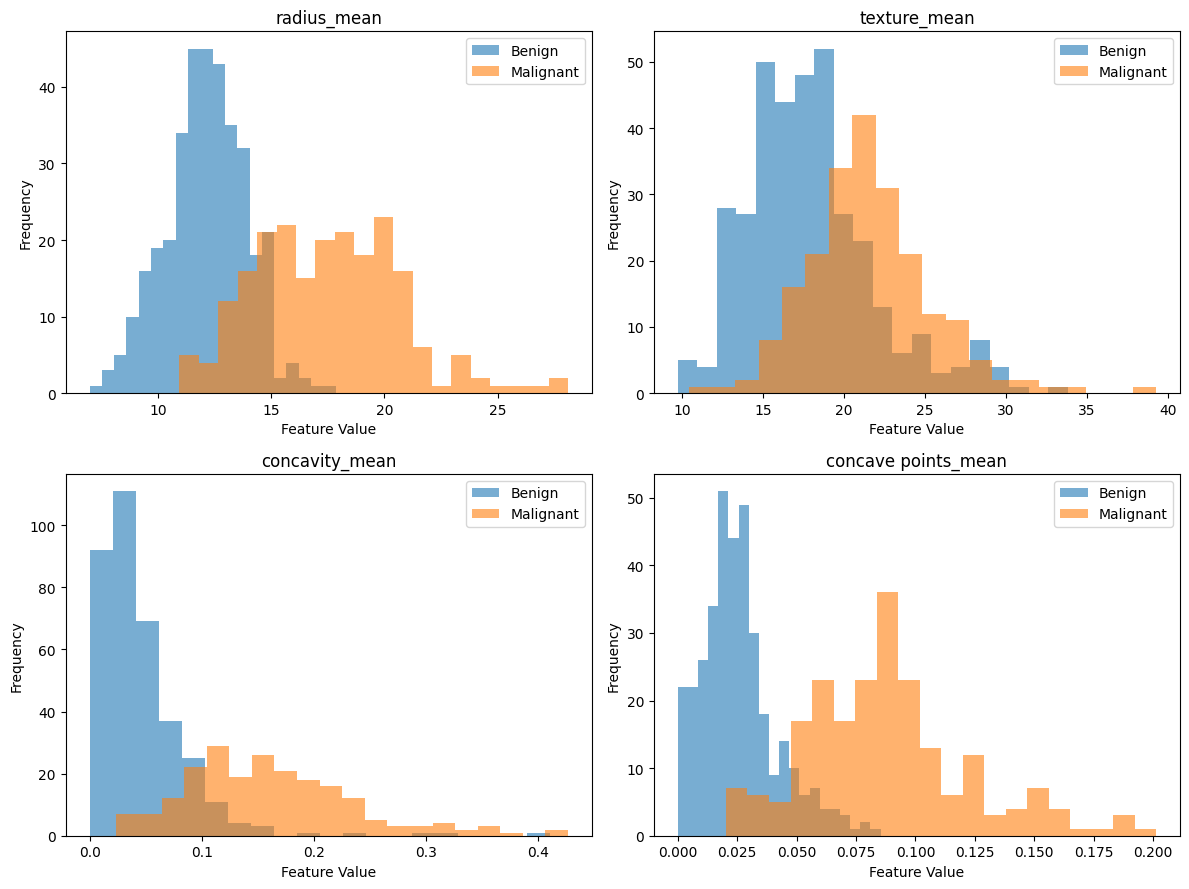

In [374]:
features_to_compare = ["radius_mean", "texture_mean", "concavity_mean", "concave points_mean"]
# these four features are examples of different morphological characteristics: nuclear size (radius_mean), texture (texture_mean) and boundary irregularity (concavity_mean and concave points_mean).

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, feature in zip(axes.flatten(), features_to_compare):
    benign_values = data[data["diagnosis"] == 0][feature]
    malignant_values = data[data["diagnosis"] == 1][feature]

    ax.hist(benign_values, bins=20, alpha=0.6, label="Benign")
    ax.hist(malignant_values, bins=20, alpha=0.6, label="Malignant")
    ax.set_title(feature)
    ax.set_xlabel("Feature Value")
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()

### 1.10 Correlation with diagnosis

In [375]:
diagnosis_correlation = data.corr()["diagnosis"].drop("diagnosis")

# sort by absolute correlation
diagnosis_correlation = diagnosis_correlation.reindex(
    diagnosis_correlation.abs().sort_values(ascending=False).index
)
print(diagnosis_correlation)

concave points_worst       0.793566
perimeter_worst            0.782914
concave points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_dimension_se       0.077972
smoothness_se             -0.067016
fractal_dimension_mean    -0

The correlation here is between each feature and the diagnosis column, which is our target (0 = benign, 1 = malignant).

For example, concave points_worst = 0.79 indicates a strong positive linear association between this feature and the diagnosis label: higher values tend to occur more often in malignant samples.
A value near 0 (like texture_se) means the feature has little linear relationship with the diagnosis.

Note: the EDA in this section uses all 569 rows, including the rows that are later set aside as the hold-out set. That is fine for describing the data.

### EDA summary

- 569 samples and 30 numeric features, with no missing values and no duplicate rows.
- 357 benign (62.7%) and 212 malignant (37.3%), so there is a mild class imbalance.
- The features are on very different scales (std from 0.0026 to 569), so they should be standardized.
- The highest correlations with diagnosis are `concave points_worst` (0.79), `perimeter_worst` (0.78), `concave points_mean` (0.78) and `radius_worst` (0.78). `texture_se`, `symmetry_se`, `fractal_dimension_mean` and `smoothness_se` are almost 0.

## 2. Hypotheses

The hypotheses come from what is known about malignant cells (enlarged nuclei with irregular outlines). The EDA is used as a first check of whether the data agrees with them. The actual test is in Part 2.

1. **Size** (radius, perimeter, area): malignant nuclei tend to be larger, so size features should be among the most useful. The EDA agrees: six of the top 8 correlations with diagnosis are size features.
2. **Shape irregularity** (concavity, concave points): malignant nuclei tend to have more irregular outlines, so these should also be strong predictors. `concave points_worst` has the highest correlation and `concave points_mean` is also near the top.
3. **Texture, smoothness, symmetry, fractal dimension** should be weaker on their own (at most about 0.46 correlation, and the `_se` ones are close to 0). I will check whether they add predictive information when combined with the other features.

**How they will be tested (Part 2):** train the same model on each feature group alone (size, shape, texture/smoothness, symmetry/fractal dimension) and on combinations, inside the cross-validation, and compare recall and AUC.

The heatmap also shows that radius, perimeter and area are almost perfectly correlated with each other. So a lot of the features are probably redundant, and feature selection might reduce the number of features without hurting performance much.

## 3. Data Preparation

The data is split into fit (70%), validation (15%) and hold-out (15%) sets. The split is stratified: benign and malignant samples are split separately so every part keeps roughly the 63/37 class ratio.

This is done to eradicate the problem of one split of data being non representable of other. This keeps the overall percentage of malignant to benign samples almost constant throughout all splits making our training data representable of real world data.

In [376]:
#helper function for adding a column of ones (bias term) to a design matrix
def add_1(X):
    X_b = np.zeros((X.shape[0],X.shape[1]+1))
    X_b[:,0] = 1
    X_b[:, 1:] = X
    return X_b

#2. Sigmoid function
def sigmoid(z):
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

In [377]:
seed = 42 #using the random seed=42 constant all throughout

def split_class(class_data, rng):
    shuffled_indices = np.arange(len(class_data))
    rng.shuffle(shuffled_indices)

    fit_size = int(0.70 * len(class_data)) #70%
    validation_size = int(0.15 * len(class_data)) #15%
    holdout_size = len(class_data) - fit_size - validation_size #15%

    fit_part = class_data.iloc[shuffled_indices[:fit_size]]
    validation_part = class_data.iloc[shuffled_indices[fit_size:fit_size + validation_size]]
    holdout_part = class_data.iloc[shuffled_indices[fit_size + validation_size:]]

    return fit_part, validation_part, holdout_part

In [378]:
rng = np.random.default_rng(seed)

benign = data[data["diagnosis"]==0]
malignant = data[data["diagnosis"]==1]
print("Number of malignant samples:", len(malignant))
print("Number of benign samples:", len(benign))

benign_fit, benign_validation, benign_holdout = split_class(benign, rng)
malignant_fit, malignant_validation, malignant_holdout = split_class(malignant, rng)

# shuffle after concatenating so the classes are not sitting in separate blocks
fit_data = pd.concat([benign_fit, malignant_fit]).sample(frac=1, random_state=seed)
validation_data = pd.concat([benign_validation, malignant_validation]).sample(frac=1, random_state=seed)
holdout_data = pd.concat([benign_holdout, malignant_holdout]).sample(frac=1, random_state=seed)

Number of malignant samples: 212
Number of benign samples: 357


The data is first separated into the two classes (malignant and benign). Each class is then split 70/15/15 separately, and the parts are concatenated and shuffled. This keeps the class ratio roughly the same in every part.

Because `int()` rounds down, the leftover rows go to the hold-out set, so the actual sizes are 397 / 84 / 88 rather than exactly 70/15/15.

In [379]:
splits = {"fit": fit_data, "validation": validation_data, "hold-out": holdout_data}

summary = {}
for name, split in splits.items():
    benign_count = (split["diagnosis"] == 0).sum()
    malignant_count = (split["diagnosis"] == 1).sum()
    malignant_percentage = round(split["diagnosis"].mean() * 100,1)

    summary[name] = {
        "Benign": benign_count,
        "Malignant": malignant_count,
        "% Malignant": malignant_percentage
    }
split_summary=pd.DataFrame(summary)
split_summary=split_summary.T

display(split_summary)

,Benign,Malignant,% Malignant
fit,249.0,148.0,37.3
validation,53.0,31.0,36.9
hold-out,55.0,33.0,37.5


Standardization uses the mean and standard deviation of the fit set only. The same values are then applied to the validation and hold-out sets. A column of ones is added for the bias term.

In [380]:
def design_matrices(training_features, *other_features):
    # standardize using training data only, then add the bias column
    mean = training_features.mean(axis=0);
    std = training_features.std(axis=0);
    result = []
    #in training set
    standardized = (training_features-mean)/std
    result.append(add_1(standardized))

    # validation and test
    for matrix in other_features:
        standardized=(matrix-mean) / std
        result.append(add_1(standardized))
    return result

X_fit, X_validate, X_holdout = design_matrices(
    fit_data.drop("diagnosis", axis=1).values,
    validation_data.drop("diagnosis", axis=1).values,
    holdout_data.drop("diagnosis", axis=1).values
)

y_fit = fit_data["diagnosis"].values
y_validate = validation_data["diagnosis"].values
y_holdout = holdout_data["diagnosis"].values

## 4. Baseline Logistic Regression

The model is trained with plain gradient descent on the binary cross-entropy (BCE) loss, run until the gradient is almost zero (converged). We are not penalising the bias term.

Three things are chosen separately:

- **Stopping tolerance**: decides when we say training has converged. It is checked first (4.0), because every later step uses it.

- **Learning rate**: this only changes how fast training converges, so it is chosen from the training loss .

- **L2 strength**: this changes the model that is learnt, so it is chosen using the validation loss (4.2).

Any technique like k fold or stratified k fold or grid search is not applied here.


### 4.0 Stopping tolerance

Training stops when the gradient norm `||grad J||` falls below a tolerance (or at 20000 iterations). Before fixing the tolerance to 1e-6 we check how much the answer changes with it.

For a fixed `lambda > 0` the loss is strongly convex, so the distance to the true optimum is bounded by `||theta - theta*|| <= ||grad J|| / lambda`. With `lambda = 0.003` a tolerance of 1e-6 therefore guarantees we are within about 3e-4 of the optimum.

For this check only, `eta = 0.5` and `lambda = 0.003` are fixed on purpose (they are not taken from the tuning in 4.1 and 4.2, which come later and use the tolerance). `theta*` is a reference optimum obtained with a very tight tolerance (1e-12).

In [381]:
MAX_ITERATIONS = 20000

def bce_loss(X,y,theta):
    z = X@theta
    return np.mean(np.logaddexp(0,z)-y*z)

def gradient(X,y,theta,l2_strength=0):
    penalty = np.ones(len(theta))
    penalty[0] = 0
    return X.T@(sigmoid(X@theta)-y)/len(y)+ l2_strength*penalty*theta

In [382]:
eta = 0.5
lam = 0.003

def train_model(X, y, tol, lam):
    weights = np.zeros(X.shape[1])
    for i in range(MAX_ITERATIONS):
        gradients = gradient(X, y, weights, lam)
        if np.linalg.norm(gradients) < tol:
            break
        weights = weights -eta*gradients
    return weights,i+1

best_weights, _ = train_model(X_fit,y_fit,1e-12,lam)
results = []
for tol in [1e-2,1e-4,1e-6,1e-8]:
    weights, iterations = train_model(X_fit,y_fit,tol,lam)
    pred = sigmoid(X_validate @weights) >= 0.5
    fn = np.sum((y_validate == 1) & (~pred))
    fp = np.sum((y_validate == 0) & pred)

    weight_distance = np.linalg.norm(weights-best_weights)
    validation_loss = bce_loss(X_validate,y_validate, weights)
    results.append([tol,iterations,weight_distance,tol/lam,validation_loss,fn, fp])

result_table = pd.DataFrame(results, columns=[
    "Tolerance", "Iterations", "Weight Distance",
    "Bound", "Validation BCE", "FN", "FP"
])

display(result_table)

,Tolerance,Iterations,Weight Distance,Bound,Validation BCE,FN,FP
0,1.000000e-02,125,1.174105,3.333333,0.077223,1,0
1,1.000000e-04,1949,0.028589,0.033333,0.080491,2,0
2,1.000000e-06,4708,0.000315,0.000333,0.080624,2,0
3,1.000000e-08,7633,0.000003,0.000003,0.080624,2,0


**Reading the table** A stricter tolerance brings `w` closer to `w*` but requires more iterations. At `1e-2`, convergence is too early, while `1e-4` gives a slightly different validation BCE. Both `1e-6` and `1e-8` achieve identical validation BCE and FN/FP (2/0), but `1e-6` converges faster (4708 vs. 7633 iterations). Hence, **`TOLERANCE = 1e-6`** is selected.

---



In [383]:
TOLERANCE = 1e-6   # stop when the gradient norm is below this (converged), chosen from the check
def train_logistic_regression(X, y, learning_rate, l2_strength=0,max_iterations=MAX_ITERATIONS,tolerance=TOLERANCE):
    w = np.zeros(X.shape[1])
    for i in range(max_iterations):
        g = gradient(X,y,w,l2_strength)
        if np.linalg.norm(g) < tolerance:
            break
        w = w -learning_rate*g
    return w

### 4.1 Learning rate

With a fixed number of iterations, the validation loss mostly reflects on how long the model was trained (a large learning rate trains further and overfits, a small one is stopped early), not which learning rate is better. So the learning rates are compared on the training loss instea of validation loss, at one middle L2 value (0.01) which is just taken to be fixed for comparision for learning rates, run to convergence.
A good learning rate reaches the same minimum quickly without jumping and never makes the loss go up.

In [384]:
learning_rates = [0.01, 0.1, 0.5 , 1.0, 1.5, 5, 10]
reference_l2 = 0.01   # only used to compare learning rates

lr_rows = []
fit_loss_curves = {}

for learning_rate in learning_rates:
    theta = np.zeros(X_fit.shape[1])
    curve = []
    converged,iterations_used = False, MAX_ITERATIONS

    for iteration in range(1,MAX_ITERATIONS+1):
        step = gradient(X_fit,y_fit,theta,reference_l2)
        if np.linalg.norm(step) < TOLERANCE:
            converged,iterations_used = True,iteration
            break
        theta = theta-learning_rate*step
        curve.append(bce_loss(X_fit,y_fit,theta) + 0.5*reference_l2*np.sum(theta[1:]**2)) # full training objective = BCE+L2 penalty(bias not penalized)

    fit_loss_curves[learning_rate] = curve
    lr_rows.append({"Learning rate": learning_rate,"Converged": converged,"Iterations": iterations_used,
                    "Final training objective": curve[-1],"Loss increases": int(np.sum(np.diff(curve) > 1e-12))})



,Converged,Iterations,Final training objective,Loss increases
Learning rate,,,,
0.01,False,20000,0.099970,0
0.10,True,7374,0.099961,0
0.50,True,1476,0.099961,0
1.00,True,743,0.099961,0
1.50,True,500,0.099961,0
5.00,True,156,0.099961,0
10.00,False,20000,0.101293,11106


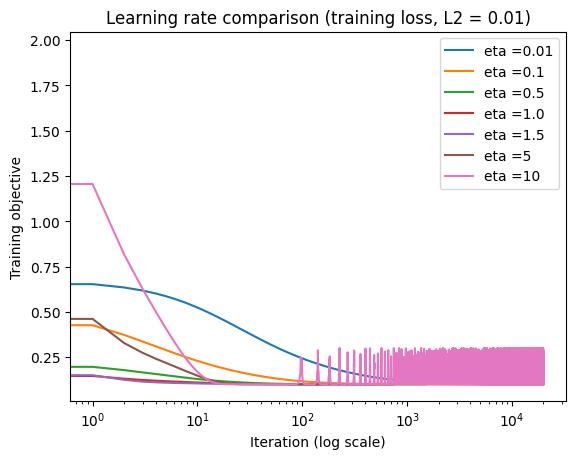

In [385]:
lr_table = pd.DataFrame(lr_rows).set_index("Learning rate")
display(lr_table)

for learning_rate in learning_rates:
    plt.plot(fit_loss_curves[learning_rate], label=f"eta ={learning_rate}")
plt.xscale("log")
plt.xlabel("Iteration (log scale)")
plt.ylabel("Training objective")
plt.title("Learning rate comparison (training loss, L2 = 0.01)")
plt.legend()
plt.show()

Here as we can see we have taken many candidates for our learning rates and for our bigger candidates our graph is moving very quickly which is showing the bouncing/jumping off the target value or minimum value which is not feasable and small learning rates to be go very slowly taking many iterations to reach to convergence.

Only few learning rates are able to converge within the iterations limit which are feasable and among them the lowest training error rate is choosen.

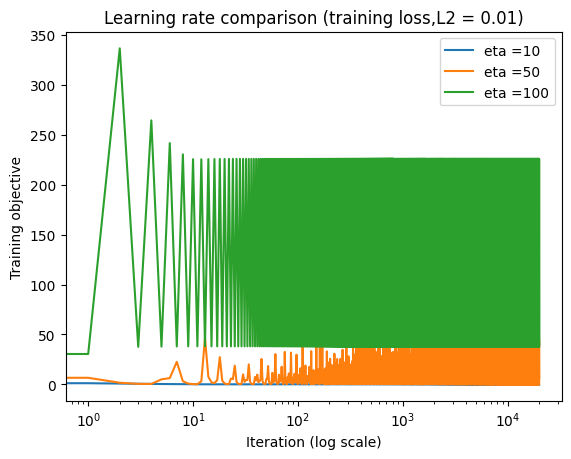

In [386]:
#plotting for higher learning rates showing the bouncing or jumping off the target
learning_rates2 = [10,50,100]
lr_rows2 = []
fit_loss_curves2 = {}
for learning_rate in learning_rates2:
    theta = np.zeros(X_fit.shape[1])
    curve = []
    converged,iterations_used = False,MAX_ITERATIONS

    for iteration in range(1,MAX_ITERATIONS+1):
        step = gradient(X_fit,y_fit,theta,reference_l2)
        if np.linalg.norm(step)<TOLERANCE:
            converged, iterations_used = True,iteration
            break
        theta = theta -learning_rate*step
        # full training objective = BCE + L2 penalty (bias not penalized)
        curve.append(bce_loss(X_fit,y_fit,theta) + 0.5*reference_l2*np.sum(theta[1:]**2))

    fit_loss_curves2[learning_rate] = curve
    lr_rows2.append({"Learning rate": learning_rate, "Converged": converged, "Iterations": iterations_used,
                    "Final training objective": curve[-1],"Loss increases": int(np.sum(np.diff(curve) > 1e-12))})

for learning_rate in learning_rates2:
    plt.plot(fit_loss_curves2[learning_rate],label=f"eta ={learning_rate}")
plt.xscale("log")
plt.xlabel("Iteration (log scale)")
plt.ylabel("Training objective")
plt.title("Learning rate comparison (training loss,L2 = 0.01)")
plt.legend()
plt.show()

In [387]:
# fastest learning rate that converged and never increased the loss
# but 0.5 is choosen the reason is given exact in the report
best_learning_rate =0.5
print("selected learning rate:",best_learning_rate)

selected learning rate: 0.5


Out of all our learning rates we have finalised our learning rate. Reason of choosing learning rate=0.5 is in the report.

### 4.2 L2 regularization

Now the models are trained to convergence for each L2 strength and compared on the validation loss.
 λ = 0 usually does not converge here because the classes are almost separable, so the weights keep growing until the iteration limit.


We will compare them by directly looking at the minimum validation loss within the iteration limit.

In [388]:
l2_strengths = [0, 1e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1,1]
l2_rows = []

for l2_strength in l2_strengths:
    theta = train_logistic_regression(X_fit, y_fit,best_learning_rate,l2_strength)
    converged = np.linalg.norm(gradient(X_fit, y_fit, theta, l2_strength)) < TOLERANCE*10
    l2_rows.append({
        "Lambda": l2_strength,
        "Validation BCE": bce_loss(X_validate, y_validate, theta),
        "Weight norm": np.sqrt(np.sum(theta[1:] ** 2)),"Converged": converged})

l2_table = pd.DataFrame(l2_rows)
display(l2_table)
best_l2_strength = l2_table.loc[l2_table["Validation BCE"].idxmin(), "Lambda"]
print("best lambda:", best_l2_strength)

,Lambda,Validation BCE,Weight norm,Converged
0,0.0000,0.324967,17.473927,False
1,0.0001,0.236564,12.128970,False
2,0.0010,0.113279,4.872047,True
3,0.0030,0.080624,3.269620,True
4,0.0100,0.084484,2.253066,True
5,0.0300,0.112119,1.607149,True
6,0.1000,0.162767,1.084517,True
7,1.0000,0.326272,0.441902,True


best lambda: 0.003


In [389]:
def lambda_sweep(eta):
    rows = []
    for lam in l2_strengths:
        with np.errstate(all="ignore"):
            w = train_logistic_regression(X_fit, y_fit,eta,lam)
            loss = bce_loss(X_validate, y_validate, w)
            norm = np.linalg.norm(w[1:])
            g = np.linalg.norm(gradient(X_fit,y_fit, w,lam))
        conv = np.isfinite(loss) and np.isfinite(norm) and g < TOLERANCE * 10
        rows.append([loss if conv or np.isfinite(loss) else np.nan,
                     norm if np.isfinite(norm) else np.nan, bool(conv)])
    return pd.DataFrame(rows, index=l2_strengths, columns=["Val. BCE", "Weight norm", "Conv."])

result5 = lambda_sweep(5)
result05 = lambda_sweep(0.5)
display(pd.concat([result5, result05], axis=1, keys=["eta = 5", "eta = 0.5"]).round(4))

eta = 5                    eta = 0.5                   
       Val. BCE Weight norm  Conv.  Val. BCE Weight norm  Conv.
0.0000   0.6820     52.0274  False    0.3250     17.4739  False
0.0001   0.2370     13.4022   True    0.2366     12.1290  False
0.0010   0.1133      4.8720   True    0.1133      4.8720   True
0.0030   0.0806      3.2696   True    0.0806      3.2696   True
0.0100   0.0845      2.2531   True    0.0845      2.2531   True
0.0300   0.1121      1.6071   True    0.1121      1.6071   True
0.1000   0.9487      3.2108  False    0.1628      1.0845   True
1.0000      NaN         NaN  False    0.3263      0.4419   True

In [390]:
# convergence (True/False) for each learning rate across the lambda grid (reuses lambda_sweep from above)
etas_to_compare = [5, 1.5, 1.0, 0.5]
conv_table = pd.DataFrame({f"eta = {e}": lambda_sweep(e)["Conv."]for e in etas_to_compare})
conv_table.index.name = "lambda"
display(conv_table)

,eta = 5,eta = 1.5,eta = 1.0,eta = 0.5
lambda,,,,
0.0000,False,False,False,False
0.0001,True,False,False,False
0.0010,True,True,True,True
0.0030,True,True,True,True
0.0100,True,True,True,True
0.0300,True,True,True,True
0.1000,False,True,True,True
1.0000,False,False,False,True


In [391]:
final_parameters = train_logistic_regression(X_fit, y_fit, best_learning_rate, best_l2_strength)
#training our final parameters on all of the fit data again after choosing our hyperparameters and our learning rate

### 4.3 Validation evaluation

Helper functions first: a confusion matrix function and the metrics.

ROC-AUC is calculated with the rank formula
(the probability that a random malignant sample gets a higher score than a random benign one).

The hold-out set is not touched until the very end of the project.

In [392]:
def confusion_matrix(y, probabilities, threshold=0.5):
    predicted_labels = (probabilities >= threshold).astype(int)
    tn = np.sum((y == 0) & (predicted_labels == 0))
    fp = np.sum((y == 0) & (predicted_labels == 1))
    fn = np.sum((y == 1) & (predicted_labels == 0))
    tp = np.sum((y == 1) & (predicted_labels == 1))
    return np.array([[tn, fp], [fn, tp]])

def roc_auc(y, probabilities):
    ranks = np.empty(len(probabilities))
    ranks[np.argsort(probabilities)] = np.arange(1, len(probabilities) + 1)
    malignant_count = np.sum(y == 1)
    benign_count = np.sum(y == 0)
    return (np.sum(ranks[y == 1]) - malignant_count * (malignant_count + 1) / 2) / (malignant_count * benign_count)

def calculate_metrics(y, probabilities, threshold=0.5):
    (tn, fp), (fn, tp) = confusion_matrix(y, probabilities, threshold)

    recall = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision=0;f1=0
    if (tp + fp) > 0: precision = tp / (tp + fp)
    else: precision=0.0
    if (precision + recall) > 0: f1 = 2 * precision * recall / (precision + recall)
    else:  f1=0.0;
    return {"recall": recall, "specificity": specificity, "precision": precision,"f1": f1, "auc": roc_auc(y, probabilities), "fp": fp, "fn": fn}

def roc_curve_points(y, p):
    y = y[np.argsort(-p)]
    tpr = np.r_[0, np.cumsum(y == 1) / np.sum(y == 1)]
    fpr = np.r_[0, np.cumsum(y == 0) / np.sum(y == 0)]
    return fpr, tpr

In [393]:
validation_probabilities = sigmoid(X_validate @ final_parameters)
validation_predictions = (validation_probabilities >= 0.5).astype(int)  #taking the threshold as 0.5

print("Validation Accuracy:", np.mean(validation_predictions == y_validate))
print("Validation BCE:", bce_loss(X_validate, y_validate, final_parameters))
print("Confusion matrix: ")
print(confusion_matrix(y_validate, validation_probabilities))

Validation Accuracy: 0.9761904761904762
Validation BCE: 0.08062429150925556
Confusion matrix: 
[[53  0]
 [ 2 29]]


In [394]:
metrics_table = pd.DataFrame({"validation": calculate_metrics(y_validate, validation_probabilities)})
display(metrics_table.round(4))

,validation
recall,0.9355
specificity,1.0000
precision,1.0000
f1,0.9667
auc,0.9957
fp,0.0000
fn,2.0000


Here at 0.5 threshold our data looks something like this table with out precision being perfect 1.0 but our recall being 0.9355.

As we are dealing in the medical field our more dangerous situation is of FN or poor recall which we will fix later below.

In [395]:
# which validation sample does the model get most wrong?
validation_z = X_validate @ final_parameters
individual_loss = np.logaddexp(0, validation_z) - y_validate * validation_z

worst_index = np.argmax(individual_loss)
print("true label:", y_validate[worst_index])
print("predicted probability:", validation_probabilities[worst_index])
print("predicted class:", validation_predictions[worst_index])
print("individual BCE:", individual_loss[worst_index])

true label: 1
predicted probability: 0.15126229916991768
predicted class: 0
individual BCE: 1.888739868551318


### 4.4 Choosing a threshold

A missed malignant case (false negative) is worse than a false alarm (false positive), so a false negative is counted as 5 times worse(for counting our medical field emergency and importance of FN or recall here).
Though this 5:1 ratio is an assumption, not a measured value. The threshold with the lowest validation cost is selected. If two thresholds have the same cost, we have taken the lower one because the priority is to miss as few malignant cases as possible.

In [396]:
false_negative_cost = 5
false_positive_cost = 1

threshold_rows = []
for threshold in np.arange(0.05, 0.96, 0.05):
    threshold_metrics = calculate_metrics(y_validate, validation_probabilities, threshold)
    cost = false_negative_cost * threshold_metrics["fn"] + false_positive_cost * threshold_metrics["fp"]
    threshold_rows.append([round(threshold, 2), threshold_metrics["fn"], threshold_metrics["fp"], cost,
                           threshold_metrics["recall"], threshold_metrics["specificity"]])

In [397]:
threshold_table = pd.DataFrame(threshold_rows, columns=["threshold", "FN", "FP", "cost", "recall", "specificity"])
display(threshold_table)

,threshold,FN,FP,cost,recall,specificity
0,0.05,0,10,10,1.000000,0.811321
1,0.10,0,8,8,1.000000,0.849057
2,0.15,0,4,4,1.000000,0.924528
3,0.20,2,3,13,0.935484,0.943396
4,0.25,2,3,13,0.935484,0.943396
5,0.30,2,1,11,0.935484,0.981132
6,0.35,2,1,11,0.935484,0.981132
7,0.40,2,1,11,0.935484,0.981132
8,0.45,2,1,11,0.935484,0.981132
9,0.50,2,0,10,0.935484,1.000000


In [398]:
# if there is a tie in cost we will take the lowest threshold (fewer missed malignant cases)
minimum_cost = threshold_table["cost"].min()
best_threshold = threshold_table.loc[threshold_table["cost"] == minimum_cost, "threshold"].min()
print("best threshold:", best_threshold)

best threshold: 0.15


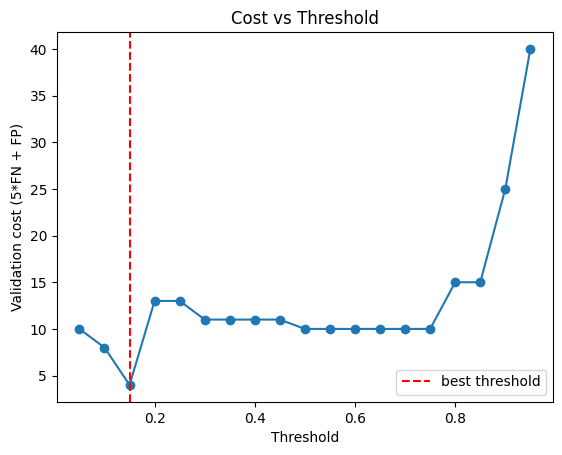

In [399]:
plt.plot(threshold_table["threshold"], threshold_table["cost"], marker="o")
plt.axvline(best_threshold, color="red", linestyle="--", label="best threshold")
plt.xlabel("Threshold")
plt.ylabel("Validation cost (5*FN + FP)")
plt.title("Cost vs Threshold")
plt.legend()
plt.show()

In [400]:
threshold_comparison = pd.DataFrame({
    "threshold 0.5": calculate_metrics(y_validate, validation_probabilities, 0.5),
    f"best threshold ({best_threshold})": calculate_metrics(y_validate, validation_probabilities, best_threshold)
})
display(threshold_comparison.round(4))

,threshold 0.5,best threshold (0.15)
recall,0.9355,1.0000
specificity,1.0000,0.9245
precision,1.0000,0.8857
f1,0.9667,0.9394
auc,0.9957,0.9957
fp,0.0000,4.0000
fn,2.0000,0.0000


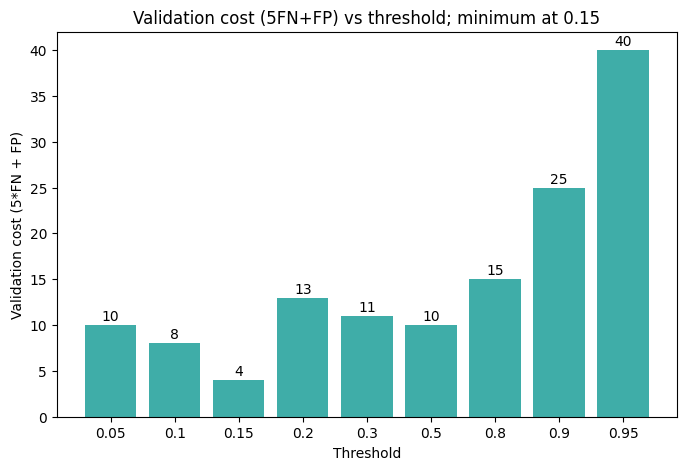

In [401]:
# validation cost vs threshold (bar chart)
shown = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50, 0.80, 0.90, 0.95]
bars = threshold_table[threshold_table["threshold"].isin(shown)]

plt.figure(figsize=(8, 5))
plt.bar(range(len(bars)), bars["cost"], color="#3fada8")
for x, c in enumerate(bars["cost"]):
    plt.text(x, c + 0.5, int(c), ha="center")
plt.xticks(range(len(bars)), bars["threshold"])
plt.xlabel("Threshold")
plt.ylabel("Validation cost (5*FN + FP)")
plt.title(f"Validation cost (5FN+FP) vs threshold; minimum at {best_threshold}")
plt.show()

We have directly saw the best threshold according to our metrics.

### 4.5 Final model

The final model is the one trained on the fit set (`final_parameters`) with the learning rate and L2 strength selected in 4.1 and 4.2. The threshold from 4.4 was tuned on the same validation set, so the validation metrics at that threshold are slightly optimistic(we have given the reason for it below).

 For now everything is evaluated on the validation set only. The hold-out set is kept sealed and will be used once, at the very end of the project.

### 4.6 Confusion matrices and ROC curve

Confusion matrices on the validation set at threshold 0.5 and at the selected threshold, and the ROC curve.

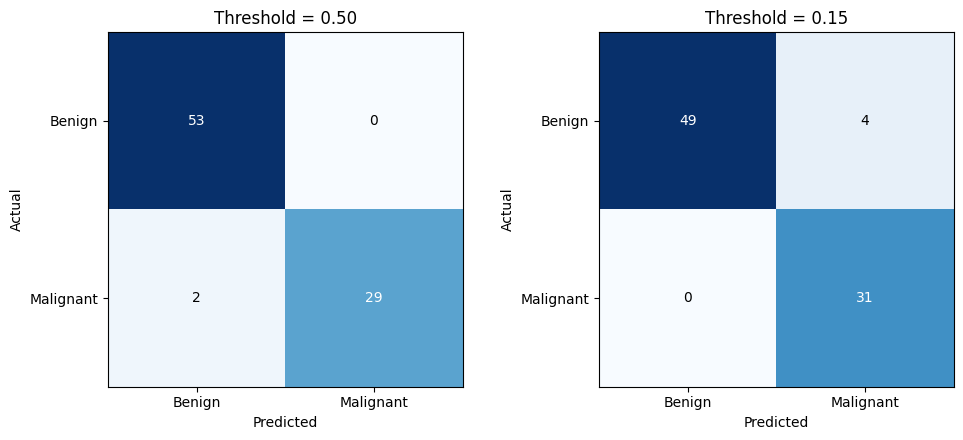

In [402]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for axis, threshold in zip(axes, [0.5, best_threshold]):
    matrix = confusion_matrix(y_validate,validation_probabilities,threshold)
    axis.imshow(matrix, cmap="Blues")
    for row in range(2):
        for column in range(2):
            text_color = (
                "white"
                if matrix[row, column] > matrix.max() / 2
                else "black"
            )
            axis.text(column,row,matrix[row, column],ha="center",va="center",color=text_color)
    axis.set_xticks([0, 1])
    axis.set_xticklabels(["Benign", "Malignant"])
    axis.set_yticks([0, 1])
    axis.set_yticklabels(["Benign", "Malignant"])
    axis.set_xlabel("Predicted")
    axis.set_ylabel("Actual")
    axis.set_title(f"Threshold = {threshold:.2f}")
plt.tight_layout()
plt.show()

As we can see here clearly by lowering down the threshold we are somewhat loosing the accuracy but we are getting our recall better because of 0 FN cases which is more important in consideration of the medical field but this also increases the FP cases although those cases are of less concern considering the field.

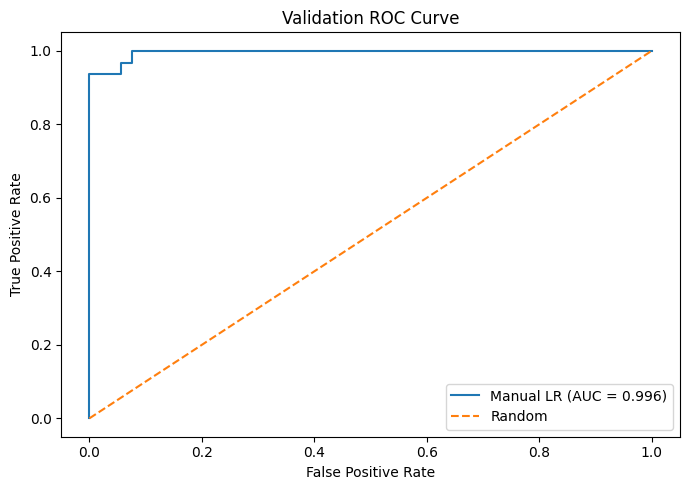

In [403]:
false_positive_rate, true_positive_rate = roc_curve_points(y_validate,validation_probabilities)
auc_score = roc_auc(y_validate,validation_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(false_positive_rate,true_positive_rate,label=f"Manual LR (AUC = {auc_score:.3f})")
plt.plot([0, 1],[0, 1],"--",label="Random")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

## 5. Exploratory Cross-Validation (fixed hyperparameters)

The validation set alone is small, so we also use 5-fold cross-validation on the fit and validation sets combined. The folds are stratified, and every fold does its own preprocessing so nothing leaks from the validation fold:

split into folds → select features (training part only) → standardize (training part only) → train → test on the validation fold → calculate metrics

The learning rate and L2 strength are the ones selected above and are kept fixed, so this is an exploratory check and not the final performance estimate.

In [404]:
# cross-validation uses fit + validation only
cv_data = pd.concat([fit_data, validation_data])
X_all = cv_data.drop("diagnosis", axis=1).values
y_all = cv_data["diagnosis"].values

In [405]:
#stratified k fold
def stratified_k_fold(y, number_of_folds=5, seed=42):
    rng= np.random.default_rng(seed)
    fold_numbers = np.zeros(len(y), dtype=int)
    for class_value in [0, 1]:
        class_indices = np.where(y == class_value)[0]
        rng.shuffle(class_indices)
        for fold, indices in enumerate(np.array_split(class_indices, number_of_folds)):
            fold_numbers[indices] = fold

    for fold in range(number_of_folds):
        yield np.where(fold_numbers != fold)[0], np.where(fold_numbers == fold)[0]

In [406]:
def fit_fold(X, y, training_indices, testing_indices, feature_selector=None,learning_rate=best_learning_rate, l2_strength=best_l2_strength):
    training_features = X[training_indices]
    testing_features = X[testing_indices]
    training_labels = y[training_indices]

    # feature selection uses the training part only
    if feature_selector is None:
        selected_features = list(range(X.shape[1]))
    else:
        selected_features = feature_selector(training_features, training_labels)

    training_matrix, test_matrix = design_matrices(training_features[:, selected_features], testing_features[:, selected_features])
    model_parameters = train_logistic_regression(training_matrix, training_labels, learning_rate, l2_strength)
    return model_parameters, test_matrix, selected_features

def cross_validate(X, y, feature_selector=None, number_of_folds=5, threshold=0.5, seed=42): #keeping same seed
    fold_results = []

    for fold, (training_indices, testing_indices) in enumerate(stratified_k_fold(y, number_of_folds, seed), start=1):
        model_parameters, test_matrix, selected_features = fit_fold(X, y, training_indices, testing_indices, feature_selector)
        probabilities = sigmoid(test_matrix @ model_parameters)
        fold_metrics = calculate_metrics(y[testing_indices], probabilities, threshold)
        fold_metrics["fold"] = fold
        fold_metrics["number_of_features"] = len(selected_features)
        fold_metrics["selected_features"] = tuple(selected_features)
        fold_results.append(fold_metrics)

    return pd.DataFrame(fold_results)

In [407]:
metric_columns = ["recall", "specificity", "f1", "auc", "fp", "fn"]

cv_results = cross_validate(X_all, y_all)
cv_summary = pd.DataFrame({
    "Mean": cv_results[metric_columns].mean(),
    "Std": cv_results[metric_columns].std()})

display(cv_summary.round(4))

# individual fold results
display(cv_results.drop(columns="selected_features"))

,Mean,Std
recall,0.9440,0.0559
specificity,0.9901,0.0090
f1,0.9622,0.0356
auc,0.9928,0.0098
fp,0.6000,0.5477
fn,2.0000,2.0000


,recall,specificity,precision,f1,auc,fp,fn,fold,number_of_features
0,0.861111,0.983607,0.968750,0.911765,0.986339,1,5,1,30
1,0.972222,0.983607,0.972222,0.972222,0.999089,1,1,2,30
2,1.000000,1.000000,1.000000,1.000000,1.000000,0,0,3,30
3,0.972222,1.000000,1.000000,0.985915,1.000000,0,1,4,30
4,0.914286,0.983333,0.969697,0.941176,0.978571,1,3,5,30


## 6. Repeated Cross-Validation

One 5-fold run depends a lot on how the folds happen to be split. So the 5-fold CV is repeated 3 times with a different seed each time (15 folds in total). Repeat 1 uses seed 42, so it is the same as the single run above.

In [408]:
def repeated_cross_validation(X, y, feature_selector=None, number_of_folds=5, number_of_repeats=3,threshold=0.5, random_seed=42):
    all_results = []
    for repeat in range(number_of_repeats):
        # different seed each repeat gives different folds
        repeat_results = cross_validate(X, y, feature_selector, number_of_folds, threshold, seed=random_seed + repeat)
        repeat_results["repeat"] = repeat + 1
        all_results.append(repeat_results)

    return pd.concat(all_results, ignore_index=True)

In [409]:
repeated_results = repeated_cross_validation(X_all, y_all)

repeated_summary = pd.DataFrame({
    "Mean": repeated_results[metric_columns].mean(),
    "Std": repeated_results[metric_columns].std()})

print("5-fold x 3 repeats, all 30 features")
display(repeated_summary.round(4))

5-fold x 3 repeats, all 30 features


,Mean,Std
recall,0.9404,0.0525
specificity,0.9879,0.0170
f1,0.9586,0.0263
auc,0.9918,0.0089
fp,0.7333,1.0328
fn,2.1333,1.8848


**Limitation:** This is exploratory, non-nested cross-validation. The learning rate, L2 strength and threshold were chosen using the validation set, and that same validation set is part of the data used here (fit + validation), so the CV estimate is slightly optimistic. Nested CV (tuning inside each training fold) is planned after midsem. The standard deviation above is over 15 folds that overlap between repeats, so it only describes the spread and is not a proper confidence interval.

### 6.1 Threshold check with out-of-fold predictions

In 4.4 the threshold was chosen from only 84 validation samples. Here every one of the 481 samples (fit + validation) gets a prediction from a model that never saw it, repeated over the 3 CV seeds, and the cost is averaged. Different FN:FP cost ratios are tried because the 5:1 ratio is an assumption.

In [410]:
def out_of_fold_probabilities(X, y, number_of_folds=5, seed=42):
    probabilities = np.zeros(len(y))
    for training_indices, testing_indices in stratified_k_fold(y, number_of_folds, seed):
        model_parameters, test_matrix, _ = fit_fold(X, y, training_indices, testing_indices)
        probabilities[testing_indices] = sigmoid(test_matrix @ model_parameters)
    return probabilities

oof_probabilities = [out_of_fold_probabilities(X_all, y_all, seed=42 + repeat) for repeat in range(3)]
candidate_thresholds = np.round(np.arange(0.05, 0.96, 0.05), 2)

def average_counts(threshold):
    counts = [confusion_matrix(y_all, probabilities, threshold) for probabilities in oof_probabilities]
    mean_matrix = np.mean(counts, axis=0)
    return mean_matrix[1, 0], mean_matrix[0, 1]   # mean FN, mean FP

In [411]:
ratio_rows = []
for ratio in [1, 2, 5, 10]:
    costs = np.array([ratio * average_counts(t)[0] + average_counts(t)[1] for t in candidate_thresholds])
    best = candidate_thresholds[costs == costs.min()].min()
    fn_at_best, fp_at_best = average_counts(best)
    fn_at_half, fp_at_half = average_counts(0.5)
    ratio_rows.append({"FN cost : FP cost": f"{ratio}:1", "best threshold": best,
                       "FN at best": round(fn_at_best, 1), "FP at best": round(fp_at_best, 1),
                       "FN at 0.5": round(fn_at_half, 1), "FP at 0.5": round(fp_at_half, 1)})

display(pd.DataFrame(ratio_rows))
oof_threshold = [row["best threshold"] for row in ratio_rows if row["FN cost : FP cost"] == "5:1"][0]
print("out-of-fold threshold for 5:1 cost:", oof_threshold)

,FN cost : FP cost,best threshold,FN at best,FP at best,FN at 0.5,FP at 0.5
0,1:1,0.60,12.7,1.3,10.7,3.7
1,2:1,0.50,10.7,3.7,10.7,3.7
2,5:1,0.25,7.3,15.3,10.7,3.7
3,10:1,0.05,2.3,49.7,10.7,3.7


out-of-fold threshold for 5:1 cost: 0.25


## Observations So Far

- **Training.** All stable learning rates reach the same minimum training loss, so the learning rate only changes speed. η = 5 converged fastest (156 iterations) but was unstable for large λ, so η = 0.5 was chosen. The best L2 strength on the validation set is 0.003. λ = 0 and 1e-4 do not converge because the classes are almost separable.
- **Validation set (threshold 0.5).** Accuracy 0.976, recall 0.936 (29 of 31 malignant found), specificity 1.0, ROC-AUC 0.996, with 2 false negatives and 0 false positives. The ranking of samples is almost perfect (AUC); the missed cases come from the 0.5 cut-off.
- **Threshold.** On the validation set alone the cost-based threshold is 0.15 (0 FN, 4 FP), but this is based on only 31 malignant cases and moved from 0.5 to 0.15 just from fixing the Cost effecctive FN:FP, so it is not reliable. With out-of-fold predictions on 481 samples, the 5:1 threshold is 0.25. Compared with 0.5 it removes about 3 false negatives (10.7 to 7.3) but adds about 12 false positives (3.7 to 15.3) per pass. The best threshold depends strongly on the assumed cost ratio (0.60 for 1:1, 0.25 for 5:1, 0.05 for 10:1), our ratio is taken from the Elkan(2001) research paper(5:1).
- **Cross-validation (30 features, threshold 0.5).** Single 5-fold: recall 0.944 ± 0.056, specificity 0.990 ± 0.009, F1 0.962, AUC 0.993. Repeated 5-fold x 3: recall 0.940 ± 0.053, specificity 0.988 ± 0.017, F1 0.959, AUC 0.992, with about 2.1 false negatives and 0.7 false positives per fold. Recall is the weakest and most variable metric as for our medical grade standard, which is why the threshold and the FN cost matter.
